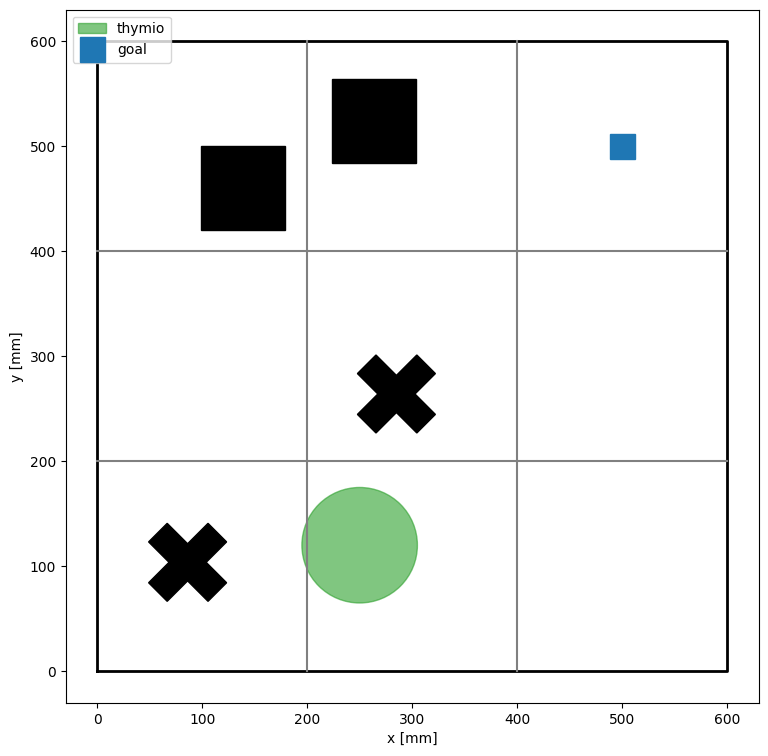

In [1]:
#MAP GENERATION

import matplotlib.pyplot as plt
from shapely.geometry import box, Polygon
from shapely.affinity import rotate
from global_navigation import ROBOT_W
import random

# --- Parametres (frame : origine en bas a gauche, x a droite, y en haut, mm) ---
ARENA_W, ARENA_H = 600, 600   # mm

CELL = 200          # mm : 600 / 3
PIECE = 80          # mm 
CROSS_THICK = 25    # mm 
# --- Formes ---

def centre_case(ligne, colonne):
    """Centre (x, y) en mm d'une case. Ligne 0 = en haut."""
    return ((colonne + 0.5) * CELL, (2 - ligne + 0.5) * CELL)

def position_aleatoire(ligne, colonne, taille):
    """Centre (x, y) en mm tire au hasard dans la case, pour qu'une piece
    de cette taille reste entierement a l'interieur."""
    marge = taille / 2 * 1.5           # demi-taille + securite pour les croix tournees
    x_min = colonne * CELL + marge
    x_max = (colonne + 1) * CELL - marge
    y_min = (2 - ligne) * CELL + marge
    y_max = (3 - ligne) * CELL - marge
    return (random.uniform(x_min, x_max), random.uniform(y_min, y_max))

def carre(cx, cy, cote, angle=0):
    h = cote / 2
    return rotate(box(cx - h, cy - h, cx + h, cy + h), angle, origin=(cx, cy))


def croix(cx, cy, taille, epaisseur, angle=45):
    a, e = taille / 2, epaisseur / 2
    c = box(cx - a, cy - e, cx + a, cy + e).union(box(cx - e, cy - a, cx + e, cy + a))
    return rotate(c, angle, origin=(cx, cy))

# --- GAMEBOARD---
gameboard = [
    ["O", "O", None],
    [None, "X", None],
    ["X", None, None],
]
obstacles = []
for ligne in range(3):
    for colonne in range(3):
        if gameboard[ligne][colonne] == "O":
            obstacles.append(carre(*position_aleatoire(ligne, colonne, PIECE), PIECE))
        elif gameboard[ligne][colonne] == "X":
            obstacles.append(croix(*position_aleatoire(ligne, colonne, PIECE), PIECE, CROSS_THICK))
goal = centre_case(0, 2)          
thymio_pos = (250, 120)   

# --- Affichage ---
def afficher_carte(obstacles, thymio_pos, goal, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 9 * ARENA_H / ARENA_W))
    ax.plot([0, ARENA_W, ARENA_W, 0, 0], [0, 0, ARENA_H, ARENA_H, 0], "k-", lw=2)
    # tic-tac-toe grid : 
    for i in range(1, 3):
        ax.plot([i * CELL, i * CELL], [0, ARENA_H], color="gray", lw=1.5)   # verticale
        ax.plot([0, ARENA_W], [i * CELL, i * CELL], color="gray", lw=1.5)   # horizontale
    for obs in obstacles:
        x, y = obs.exterior.xy
        ax.fill(x, y, color="black")
    # Thymio dessine a sa vraie taille : un disque de rayon ROBOT_W / 2
    ax.add_patch(plt.Circle(thymio_pos, ROBOT_W / 2, color="tab:green", alpha=0.6, label="thymio"))
    ax.plot(*goal, "s", color="tab:blue", ms=18, label="goal")
    ax.set_aspect("equal")
    ax.set_xlim(-30, ARENA_W + 30)
    ax.set_ylim(-30, ARENA_H + 30)
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.legend(loc="upper left")
    return ax

afficher_carte(obstacles, thymio_pos, goal)
plt.show()

Path length: 495 mm
Waypoints: [(250.0, 120.0), (304.4515389641164, 120.84075168375146), (428.19522567176244, 244.58443839139707), (500.0, 500.0)]


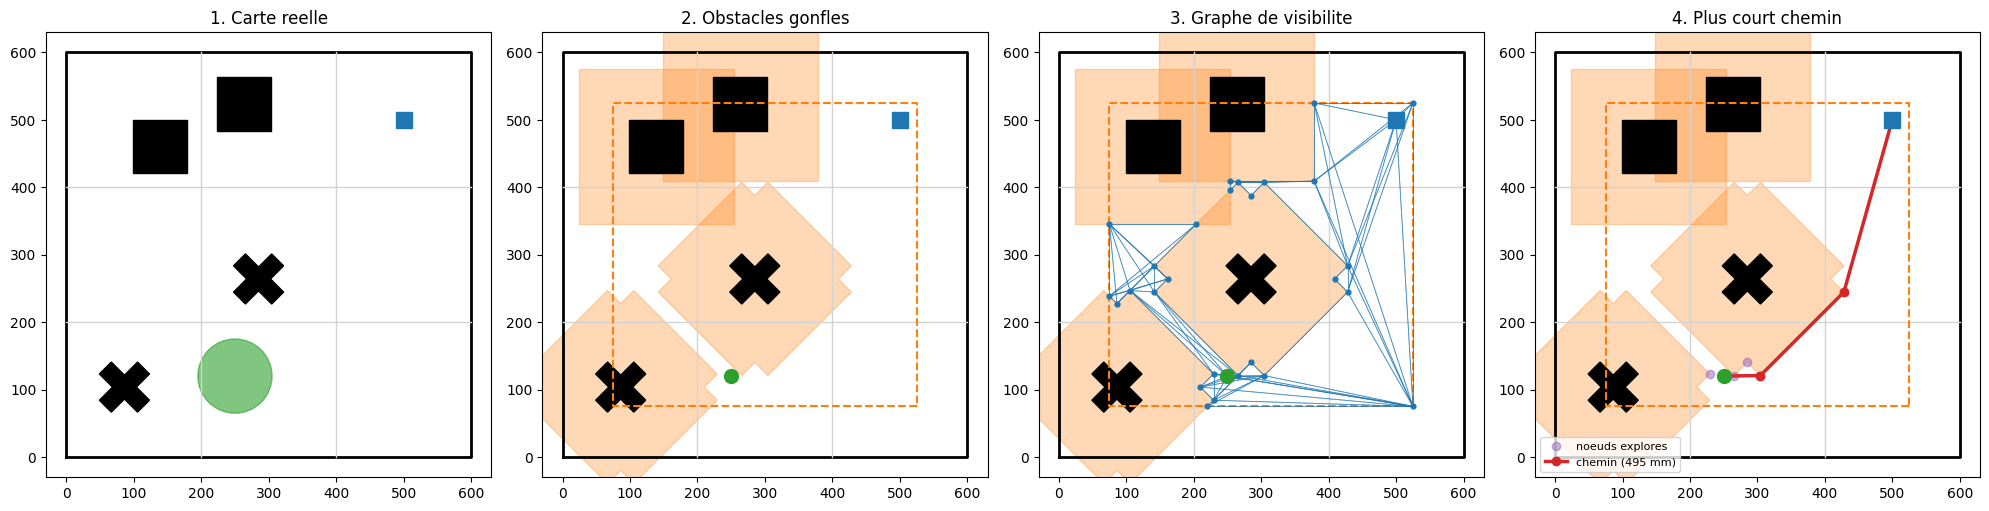

In [2]:

from global_navigation import plan_path, afficher_etapes
result = plan_path(obstacles, thymio_pos, goal, ARENA_W, ARENA_H)

if result["error"]:
    print(result["error"])
else:
    print(f"Path length: {result['length']:.0f} mm")
    print("Waypoints:", result["waypoints"])

afficher_etapes(obstacles, thymio_pos, goal, result, ARENA_W, ARENA_H, ROBOT_W, cell=CELL)
plt.show()